# KBM parallel extent against the physics parameters of the kbm_free hypercubes (Fusion_PhD-kurr.2)

**Question.** How does the parallel extent of GS2 KBMs depend on the eight sampled parameters (and on the derived $\beta'$ and $\alpha$)? Does a power law like the MTM one ($\theta_{95} \propto k_y^{a}\hat s^{b} q^{d}$, `results/mtm_extent_law_refit`) hold, which parameters matter, and are the exponents shared across the four equilibria? **No new runs; advisory.**

**Data.** The four free-parity GS2 Latin hypercubes `GS2/Runs/LATIN_HYPERCUBE/<case>/kbm_free` (SPR-045, M1, R3, R4; 1000 samples each, saved after the option-B reruns). Each `pyroscan.nc` is pyro's `time_mode="average"` reduction (last 20 % of the time trace), and holds the tearing parameter computed by pyro at save time.

**Extent.** pyrokinetics `Extent`: 95 % full span in $\theta$ (in $\pi$) of $|\phi|^2+|A_\parallel|^2$ from the cube's `eigenfunctions_squared` (the MTM law's field choice). $\phi$-only is reported beside it.

**Population.** User classifier (`general_analysis.mode_classification.classify`, docs/mode_filtering.md): KBM = $T<0.05$, $\omega>0$, $0.25<\chi_e/\chi_i<4$. Then $\gamma>0$ and converged (`growth_rate_tolerance` < 0.01). Box contact ($\ge 1\%$ of the power in $|\theta|>0.9\,\theta_{\max}$) is kept as **right-censored** (Tobit fit), not dropped.

**Parameters** are the cube coordinates. $\beta'$ and $\alpha=-q^2 R_0\beta'$ come from each sample's Pyro (`scan.sample_pyro`), after re-applying the run relations GyroRun used (see the next cell).

In [1]:
import os, sys, json, warnings, re
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy import stats, optimize
from matplotlib.ticker import StrMethodFormatter
from dotenv import load_dotenv
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics import Diagnostics
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.pyroscan import PyroScanGKOutput

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from general_analysis.mode_classification import classify, ION_DIRECTION

warnings.filterwarnings("ignore")
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams.update({"axes.titlesize": 16, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 12})  # PLOTTING_AND_PUBLISHING 4a
load_dotenv(ROOT / "local.env", override=True)
lhc = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2/Runs/LATIN_HYPERCUBE"
plot_dir = ROOT / "Plots" / "kbm_extent_vs_physics_parameters"
plot_dir.mkdir(parents=True, exist_ok=True)

databases = ["SPR-045", "M1", "R3", "R4"]
TOLERANCE_MAX, EDGE_MIN = 1e-2, 1e-2
sampled = ["ky", "q", "shat", "beta", "ion_temp_gradient", "electron_temp_gradient", "electron_dens_gradient", "electron_nu"]
derived = ["beta_prime", "alpha"]   # |beta'| and alpha = -q^2 R0 beta', from each sample's Pyro
symbol = dict(ky=r"$k_y\rho$", q="$q$", shat=r"$\hat s$", beta=r"$\beta$", ion_temp_gradient="$a/L_{Ti}$",
              electron_temp_gradient="$a/L_{Te}$", electron_dens_gradient="$a/L_{n}$", electron_nu=r"$\nu_e$",
              beta_prime=r"$|\beta'|$", alpha=r"$\alpha$")
colour = dict(zip(databases, ["C0", "C1", "C2", "C3"]))

def plain_ticks(ax):
    "Log axes: 1-2-5 ticks inside the limits, plain {x:g} labels, no minor ticks."
    for axis, lim, setter in ((ax.xaxis, ax.get_xlim(), ax.set_xticks), (ax.yaxis, ax.get_ylim(), ax.set_yticks)):
        if axis.get_scale() != "log": continue
        ticks = [m * 10.0 ** e for e in range(int(np.floor(np.log10(lim[0]))) - 1, int(np.ceil(np.log10(lim[1]))) + 1) for m in ((1, 2, 5) if np.log10(lim[1] / lim[0]) <= 2 else (1,))]
        setter([v for v in ticks if lim[0] <= v <= lim[1]]); axis.set_major_formatter(StrMethodFormatter("{x:g}"))
        axis.set_minor_formatter(plt.NullFormatter()); axis.set_minor_locator(plt.NullLocator())
        (ax.set_xlim if axis is ax.xaxis else ax.set_ylim)(lim)

## Load, and per-sample physics from pyro

One `PyroHypercube` per database from its `pyroscan.json`, with its `pyroscan.nc` attached; each database is processed completely, then released, before the next is loaded. **This order matters:** with all four scans loaded at once, R3's $\beta'$ came out 8 % off (−0.6466 against the deck's −0.5986, sample 3), while R3 alone, or R3 before R4, reproduces the deck exactly. The R3/R4 bases put $\beta'$ in an unsuffixed `bref_Bgeo` unit shared between scans (a pyro units issue, raised on Fusion_PhD-kurr.2, not patched here). The check at the end of each database guards it.

**The run relations are re-applied here.** GyroRun built these decks by setting the sampled values, then: every ion's $a/L_n$ = the electron's, every ion's $a/L_T$ = the first ion's, `enforce_quasineutrality("electron")`, `enforce_consistent_beta_prime()` (`results/kbm_gs2_1000/config_<case>.yaml`). It attached those as an unnamed function, which `pyroscan.json` does not store, so `sample_pyro` alone returns the base deck's ion gradients and $\beta'$. The same pyro calls are made below and checked against the deck GS2 actually read (embedded in `input.out.nc`) for three samples per database. Ion $\nu$ is not re-linked: it enters neither $\chi$ nor $\beta'$.

$\chi_s=(Q_s-\tfrac32 T_s\Gamma_s)/(n_sT_s\,a/L_{Ts})$, summed over the ions for $\chi_i$, as in `mode_classification.indicators`. Extent per sample after dropping the NaN padding of the union $\theta$ grid.

In [2]:
rows, check_samples = [], [3, 400, 900]
for database in databases:
    leaf = lhc / database / "kbm_free"
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.pint.dequantify()
    print(database, dict(output.sizes), "| species", scan.base_pyro.local_species.names)
    heat, particle = output["heat"].sum("field"), output["particle"].sum("field")
    check_gradients = {}
    for index, sample_name in enumerate(np.asarray(output.sample_name.values, dtype=str)):
        pyro = scan.sample_pyro(index)
        species = pyro.local_species
        ions = [name for name in species.names if name != "electron"]
        for ion in ions:
            species[ion].inverse_ln = species.electron.inverse_ln
            species[ion].inverse_lt = species[ions[0]].inverse_lt
        species.enforce_quasineutrality("electron")
        pyro.enforce_consistent_beta_prime()
        if index in check_samples:
            check_gradients[sample_name] = sorted([float(species[s].inverse_lt.m) for s in species.names] + [float(species[s].inverse_ln.m) for s in species.names])

        def chi(group):
            transport = sum(float(heat.sel(sample=index, species=s)) - 1.5 * species[s].temp.m * float(particle.sel(sample=index, species=s)) for s in group)
            drive = sum(species[s].dens.m * species[s].temp.m * species[s].inverse_lt.m for s in group)
            return transport / drive

        eigenfunction_power = output["eigenfunctions_squared"].isel(sample=index, kx=0)
        both_fields = eigenfunction_power.sel(field=["phi", "apar"]).sum("field", skipna=False).dropna("theta")
        phi_only = eigenfunction_power.sel(field="phi").dropna("theta")
        extent = {}
        for name, power in (("extent", both_fields), ("extent_phi", phi_only)):
            if power.theta.size < 2:
                extent[name] = np.nan; continue
            wrapped = PyroScanGKOutput(xr.Dataset({"eigenfunctions_squared": power}))
            Extent(wrapped)
            extent[name] = float(wrapped["extent"]) / np.pi
        theta = both_fields.theta.values
        edge = float(np.trapezoid(both_fields.values * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(both_fields.values, theta)) if theta.size > 1 else np.nan
        beta_prime = float(pyro.local_geometry.beta_prime.m)
        rows.append(dict(database=database, sample=sample_name, **{p: float(output[p][index]) for p in sampled},
                         beta_prime=abs(beta_prime), alpha=-float(pyro.local_geometry.q) ** 2 * float(pyro.local_geometry.Rmaj.m) * beta_prime,
                         theta_max=float(abs(theta).max()) / np.pi if theta.size else np.nan,
                         gamma=float(output["growth_rate"][index]), omega=ION_DIRECTION * float(output["mode_frequency"][index]),
                         T=float(output["tearing_parameter"][index]), tolerance=float(output["growth_rate_tolerance"][index]),
                         chi_ratio=chi(["electron"]) / chi(ions), edge=edge, **extent))
        # ideal-ballooning growth rate (theta0 = 0) of this sample's geometry and beta', only for unstable KBMs (cost)
        if classify(rows[-1]) == "KBM" and rows[-1]["gamma"] > 0:
            gamma_ideal = Diagnostics(pyro).ideal_ballooning_solver()
            rows[-1]["gamma_ideal"] = float(getattr(gamma_ideal, "m", gamma_ideal))

    # provenance check: beta' (beta_prime_input) and every tprim/fprim of the deck GS2 stored in input.out.nc
    for sample_name, pyro_gradients in check_gradients.items():
        with xr.open_dataset(leaf / sample_name / "input.out.nc") as run_output:
            deck = "\n".join(b"".join(line).decode().strip() for line in run_output["input_file"].values)
        deck_beta_prime = float(re.search(r"beta_prime_input\s*=\s*([-\d.eE+]+)", deck).group(1))
        deck_gradients = sorted(float(v) for v in re.findall(r"^\s*[tf]prim\s*=\s*([-\d.eE+]+)", deck, re.M))
        notebook_beta_prime = -next(row["beta_prime"] for row in rows if row["database"] == database and row["sample"] == sample_name)
        print(f"  check {sample_name}: beta' deck {deck_beta_prime:+.6f} notebook {notebook_beta_prime:+.6f} | gradients max |diff| {np.max(np.abs(np.array(deck_gradients) - pyro_gradients)):.1e}")
        assert abs(notebook_beta_prime / deck_beta_prime - 1) < 1e-6
    del scan, output, heat, particle

samples = pd.DataFrame(rows)
samples["label"] = classify(samples)
print(samples.groupby("database", sort=False).label.value_counts().unstack().to_string())

SPR-045 {'sample': 1000, 'field': 3, 'species': 3, 'theta': 1296, 'kx': 1} | species ['ion1', 'ion2', 'electron']


  check sample_0003: beta' deck -0.237647 notebook -0.237647 | gradients max |diff| 0.0e+00
  check sample_0400: beta' deck -1.954792 notebook -1.954792 | gradients max |diff| 0.0e+00
  check sample_0900: beta' deck -1.469511 notebook -1.469511 | gradients max |diff| 0.0e+00


M1 {'sample': 1000, 'field': 3, 'species': 2, 'theta': 10383, 'kx': 1} | species ['electron', 'ion1']


  check sample_0003: beta' deck -2.311281 notebook -2.311281 | gradients max |diff| 0.0e+00
  check sample_0400: beta' deck -2.870501 notebook -2.870501 | gradients max |diff| 0.0e+00
  check sample_0900: beta' deck -1.918503 notebook -1.918503 | gradients max |diff| 0.0e+00


R3 {'sample': 1000, 'field': 3, 'species': 2, 'theta': 67797, 'kx': 1} | species ['electron', 'ion1']


  check sample_0003: beta' deck -0.598581 notebook -0.598581 | gradients max |diff| 0.0e+00
  check sample_0400: beta' deck -0.435969 notebook -0.435969 | gradients max |diff| 0.0e+00
  check sample_0900: beta' deck -0.946787 notebook -0.946787 | gradients max |diff| 0.0e+00


R4 {'sample': 1000, 'field': 3, 'species': 2, 'theta': 103563, 'kx': 1} | species ['electron', 'ion1']


  check sample_0003: beta' deck -1.175985 notebook -1.175985 | gradients max |diff| 0.0e+00
  check sample_0400: beta' deck -0.941783 notebook -0.941783 | gradients max |diff| 0.0e+00
  check sample_0900: beta' deck -1.221126 notebook -1.221126 | gradients max |diff| 0.0e+00


label     KBM  mixed  MTM
database                 
SPR-045   275    628   97
M1        174    606  220
R3        215    478  307
R4        252    476  272


## Population and counts

Drops in order: not labelled KBM, $\gamma\le0$, not converged (tolerance $\ge 0.01$ or NaN). Survivors split into **kept** (edge < 1e-2) and **censored** (box contact; the extent is a lower bound).

In [3]:
unstable_kbm = (samples.label == "KBM") & (samples.gamma > 0)
converged = samples.tolerance < TOLERANCE_MAX
population = samples[unstable_kbm & converged & samples.extent.notna()].assign(censored=lambda d: d.edge >= EDGE_MIN)
counts = pd.DataFrame({
    "loaded": samples.groupby("database").size(), "gamma finite": samples[samples.gamma.notna()].groupby("database").size(),
    "KBM": samples[samples.label == "KBM"].groupby("database").size(), "KBM gamma>0": samples[unstable_kbm].groupby("database").size(),
    "converged": population.groupby("database").size(), "kept": population[~population.censored].groupby("database").size(),
    "censored": population[population.censored].groupby("database").size(),
    "median tolerance (KBM gamma>0)": samples[unstable_kbm].groupby("database").tolerance.median(),
}).reindex(databases).fillna(0)
print(counts.to_string())

          loaded  gamma finite  KBM  KBM gamma>0  converged  kept  censored  median tolerance (KBM gamma>0)
database                                                                                                   
SPR-045     1000          1000  275          228        190   190       0.0                        0.000520
M1          1000           999  174          155        140   140       0.0                        0.000031
R3          1000          1000  215          202        182   182       0.0                        0.000458
R4          1000           993  252          220        204   204       0.0                        0.000366


### Extent distribution per database

Quantiles of $\theta_{95}$ [$\pi$], the share above $1.5\pi$, the largest edge fraction (box contact needs $\ge 10^{-2}$), and the median $\theta$ box half-width [$\pi$].

In [4]:
distribution = population.groupby("database").extent.quantile([0.05, 0.5, 0.95]).unstack().rename(columns=lambda q: f"p{int(q * 100)}")
distribution["share > 1.5 pi"] = population.groupby("database").extent.apply(lambda e: (e > 1.5).mean())
distribution["max edge"] = population.groupby("database").edge.max()
distribution["theta box [pi]"] = population.groupby("database").theta_max.median()
print(distribution.reindex(databases).round(4).to_string())

              p5     p50     p95  share > 1.5 pi  max edge  theta box [pi]
database                                                                  
SPR-045   0.5412  0.7986  2.2876          0.0842    0.0088             5.0
M1        0.5980  0.8124  1.7560          0.0857    0.0071             5.0
R3        0.5638  0.7832  1.7341          0.0769    0.0046             5.0
R4        0.5407  0.7412  1.0716          0.0098    0.0020             5.0


## Fits

$\ln\theta_{95} = c_{\rm db} + \sum_j a_j \ln p_j$ over the eight sampled parameters. **Tobit** (right-censored Gaussian likelihood: a censored mode contributes $P(\ln\theta > \text{measured})$). 95 % CI from a 200-sample bootstrap. Drop-one $\Delta$AIC = AIC without that parameter − AIC with all; $>0$ means the parameter is needed. Per database, and pooled with one intercept per database (shared exponents, surface-specific prefactor).

In [5]:
def design(data, names, intercepts=("all",)):
    columns = [np.ones(len(data))] if intercepts == ("all",) else [(data.database == db).values.astype(float) for db in intercepts]
    return np.column_stack(columns + [np.log(data[name].values) for name in names])

def tobit_fit(design_matrix, log_extent, censored, start):
    def negative_log_likelihood(parameters):
        z = (log_extent - design_matrix @ parameters[:-1]) / np.exp(parameters[-1])
        return -(stats.norm.logpdf(z[~censored]) - parameters[-1]).sum() - stats.norm.logsf(z[censored]).sum()
    result = optimize.minimize(negative_log_likelihood, start, method="BFGS")
    return result.x, result.fun

def tobit(data, names, intercepts=("all",), n_boot=200, seed=0):
    design_matrix, log_extent, censored = design(data, names, intercepts), np.log(data.extent.values), data.censored.values
    start = np.r_[np.linalg.lstsq(design_matrix, log_extent, rcond=None)[0], np.log(np.std(log_extent))]
    best, negative_log_likelihood = tobit_fit(design_matrix, log_extent, censored, start)
    fit = dict(names=names, n_intercepts=len(intercepts), b=best[:-1], sigma=float(np.exp(best[-1])), n=len(data),
               n_censored=int(censored.sum()), aic=2 * len(best) + 2 * negative_log_likelihood, loglik=-negative_log_likelihood)
    if n_boot:
        rng = np.random.default_rng(seed)
        boot = np.array([tobit_fit(design_matrix[i], log_extent[i], censored[i], best)[0]
                         for i in (rng.integers(0, len(log_extent), len(log_extent)) for _ in range(n_boot))])
        low, high = np.percentile(boot[:, :-1], [2.5, 97.5], axis=0)
        fit["ci"] = (high - low) / 2
    return fit

def slopes(fit):
    return dict(zip(fit["names"], fit["b"][fit["n_intercepts"]:]))

fits, drop_one = {}, {}
for group in databases + ["pooled"]:
    data = population if group == "pooled" else population[population.database == group]
    intercepts = tuple(databases) if group == "pooled" else ("all",)
    fits[group] = tobit(data, sampled, intercepts)
    drop_one[group] = {name: tobit(data, [p for p in sampled if p != name], intercepts, n_boot=0)["aic"] - fits[group]["aic"] for name in sampled}
    ci = dict(zip(sampled, fits[group]["ci"][fits[group]["n_intercepts"]:]))
    fits[group]["r2"] = 1 - fits[group]["sigma"] ** 2 / np.var(np.log(data.extent))
    print(f"{group} (n={fits[group]['n']}, censored {fits[group]['n_censored']}, sigma {fits[group]['sigma']:.3f}, R2 {fits[group]['r2']:.3f}, var(ln extent) {np.var(np.log(data.extent)):.3f}):")
    print("   " + "  ".join(f"{name} {slope:+.3f}±{ci[name]:.3f} [dAIC {drop_one[group][name]:+.1f}]" for name, slope in slopes(fits[group]).items()))

SPR-045 (n=190, censored 0, sigma 0.398, R2 0.189, var(ln extent) 0.195):
   ky +0.023±0.051 [dAIC -1.3]  q +0.097±0.208 [dAIC -1.1]  shat -0.160±0.109 [dAIC +11.6]  beta +0.062±0.095 [dAIC +0.9]  ion_temp_gradient +0.137±0.085 [dAIC +4.3]  electron_temp_gradient +0.073±0.076 [dAIC +1.5]  electron_dens_gradient -0.054±0.079 [dAIC +0.9]  electron_nu +0.027±0.055 [dAIC -1.3]


M1 (n=140, censored 0, sigma 0.365, R2 0.173, var(ln extent) 0.161):
   ky +0.108±0.059 [dAIC +9.5]  q -0.089±0.223 [dAIC -1.3]  shat -0.002±0.096 [dAIC -2.0]  beta -0.045±0.086 [dAIC -0.8]  ion_temp_gradient +0.146±0.113 [dAIC +6.3]  electron_temp_gradient +0.007±0.069 [dAIC -2.0]  electron_dens_gradient -0.086±0.086 [dAIC +4.4]  electron_nu -0.033±0.062 [dAIC -1.1]


R3 (n=182, censored 0, sigma 0.346, R2 0.164, var(ln extent) 0.143):
   ky +0.103±0.047 [dAIC +15.3]  q +0.036±0.232 [dAIC -1.8]  shat -0.071±0.068 [dAIC +1.9]  beta +0.008±0.084 [dAIC -1.9]  ion_temp_gradient +0.069±0.081 [dAIC +1.0]  electron_temp_gradient +0.018±0.060 [dAIC -1.7]  electron_dens_gradient -0.018±0.070 [dAIC -1.6]  electron_nu +0.030±0.053 [dAIC -0.5]


R4 (n=204, censored 0, sigma 0.200, R2 0.214, var(ln extent) 0.051):
   ky +0.044±0.031 [dAIC +7.2]  q -0.032±0.146 [dAIC -1.7]  shat -0.026±0.037 [dAIC -0.1]  beta -0.056±0.056 [dAIC +6.7]  ion_temp_gradient +0.021±0.051 [dAIC -1.2]  electron_temp_gradient -0.051±0.029 [dAIC +7.0]  electron_dens_gradient +0.002±0.027 [dAIC -2.0]  electron_nu +0.025±0.028 [dAIC +0.8]


pooled (n=716, censored 0, sigma 0.343, R2 0.143, var(ln extent) 0.137):
   ky +0.069±0.024 [dAIC +28.2]  q +0.014±0.107 [dAIC -1.9]  shat -0.073±0.034 [dAIC +14.2]  beta +0.003±0.039 [dAIC -2.0]  ion_temp_gradient +0.085±0.037 [dAIC +14.3]  electron_temp_gradient +0.012±0.028 [dAIC -1.5]  electron_dens_gradient -0.035±0.036 [dAIC +4.7]  electron_nu +0.017±0.024 [dAIC -0.2]


## Are the exponents shared across the four databases? Does a power law hold?

**Sharing.** Likelihood-ratio test of the pooled fit (one intercept per database, shared exponents) against the four separate fits, and, parameter by parameter, of letting only that exponent differ by database (3 extra degrees of freedom).
**Power law.** For each parameter, $\Delta$AIC of adding $(\ln p)^2$ to the pooled fit: a large drop means the dependence curves in log-log, so a single exponent misdescribes it.

In [6]:
pooled = fits["pooled"]
separate_loglik = sum(fits[db]["loglik"] for db in databases)
extra_df = sum(len(fits[db]["b"]) + 1 for db in databases) - (len(pooled["b"]) + 1)
lr_all = 2 * (separate_loglik - pooled["loglik"])
print(f"all exponents shared vs separate: LR {lr_all:.1f} on {extra_df} df, p = {stats.chi2.sf(lr_all, extra_df):.2e}")
sharing, curvature = {}, {}
for name in sampled:
    interacted = population.assign(**{f"{name}@{db}": np.where(population.database == db, population[name], 1.0) for db in databases[1:]})
    fit_interacted = tobit(interacted, sampled + [f"{name}@{db}" for db in databases[1:]], tuple(databases), n_boot=0)
    lr = 2 * (fit_interacted["loglik"] - pooled["loglik"])
    sharing[name] = dict(LR=lr, p=stats.chi2.sf(lr, len(databases) - 1),
                         per_database={db: fits[db]["b"][1 + sampled.index(name)] for db in databases})
    squared = population.assign(**{f"{name}_sq": np.exp(np.log(population[name]) ** 2)})
    curvature[name] = tobit(squared, sampled + [f"{name}_sq"], tuple(databases), n_boot=0)["aic"] - pooled["aic"]
    print(f"{name:24s} sharing LR {lr:6.1f} p={sharing[name]['p']:.1e} | per db " + " ".join(f"{v:+.2f}" for v in sharing[name]["per_database"].values())
          + f" | add (ln p)^2: dAIC {curvature[name]:+.1f}")

all exponents shared vs separate: LR 144.1 on 27 df, p = 6.09e-18
ky                       sharing LR    6.3 p=9.8e-02 | per db +0.02 +0.11 +0.10 +0.04 | add (ln p)^2: dAIC -0.1
q                        sharing LR    0.4 p=9.4e-01 | per db +0.10 -0.09 +0.04 -0.03 | add (ln p)^2: dAIC -15.6


shat                     sharing LR    8.6 p=3.5e-02 | per db -0.16 -0.00 -0.07 -0.03 | add (ln p)^2: dAIC -12.5
beta                     sharing LR    4.3 p=2.3e-01 | per db +0.06 -0.05 +0.01 -0.06 | add (ln p)^2: dAIC -14.8
ion_temp_gradient        sharing LR    4.9 p=1.8e-01 | per db +0.14 +0.15 +0.07 +0.02 | add (ln p)^2: dAIC +2.0


electron_temp_gradient   sharing LR    8.7 p=3.4e-02 | per db +0.07 +0.01 +0.02 -0.05 | add (ln p)^2: dAIC +1.8
electron_dens_gradient   sharing LR    8.9 p=3.1e-02 | per db -0.05 -0.09 -0.02 +0.00 | add (ln p)^2: dAIC -0.8
electron_nu              sharing LR    2.6 p=4.5e-01 | per db +0.03 -0.03 +0.03 +0.03 | add (ln p)^2: dAIC -3.8


## Derived parameters: $|\beta'|$ and $\alpha$

$\beta'$ and $\alpha$ are functions of the sampled axes ($\beta$, the gradients, $q$), so they cannot enter the joint fit beside them. Two checks: (1) the pooled fit with $\beta$ replaced by $\alpha$ (AIC against the sampled-axis fit); (2) the partial slope of $\ln\alpha$ on the residual of the full sampled-axis fit (what $\alpha$ explains that the axes do not).

In [7]:
derived_fits = {}
for name in derived:
    alternative = tobit(population, [p if p != "beta" else name for p in sampled], tuple(databases))
    derived_fits[name] = alternative
    ci = dict(zip(alternative["names"], alternative["ci"][len(databases):]))
    print(f"beta -> {name}: AIC {alternative['aic'] - pooled['aic']:+.1f} vs sampled-axis fit; {name} exponent {slopes(alternative)[name]:+.3f}±{ci[name]:.3f}")
kept = population[~population.censored]
pooled_prediction = design(kept, sampled, tuple(databases)) @ pooled["b"]
for name in derived:
    fit_line = stats.linregress(np.log(kept[name]), np.log(kept.extent) - pooled_prediction)
    print(f"partial slope of residual on ln {name} (kept, n={len(kept)}): {fit_line.slope:+.3f}±{1.96 * fit_line.stderr:.3f}")

beta -> beta_prime: AIC -0.4 vs sampled-axis fit; beta_prime exponent +0.010±0.041


beta -> alpha: AIC -0.4 vs sampled-axis fit; alpha exponent +0.010±0.041
partial slope of residual on ln beta_prime (kept, n=716): +0.004±0.022
partial slope of residual on ln alpha (kept, n=716): +0.006±0.028


## The extended tail ($\theta_{95} > 1.5\pi$)

The bulk of the KBMs sits at $\theta_{95}\approx 0.5$–$1\pi$; a minority extends to $2$–$6\pi$ (Figure 1). Pooled over databases: the median of each quantity in the tail and in the bulk, and a Mann–Whitney p-value. $\gamma_{\rm ideal}$ is pyro's `Diagnostics.ideal_ballooning_solver` ($\theta_0=0$) on each sample's own geometry and $\beta'$; it depends on geometry and $\beta'$ only, not on $k_y$ or the kinetic parameters.

In [8]:
extended = population.extent > 1.5
print("extended per database:", population[extended].groupby("database").size().reindex(databases).fillna(0).astype(int).to_dict())
comparison = []
for name in sampled + derived + ["gamma", "omega", "T", "chi_ratio", "gamma_ideal"]:
    tail_values, bulk_values = population.loc[extended, name].dropna(), population.loc[~extended, name].dropna()
    comparison.append(dict(quantity=name, tail_median=tail_values.median(), bulk_median=bulk_values.median(),
                           p=stats.mannwhitneyu(tail_values, bulk_values).pvalue))
comparison = pd.DataFrame(comparison)
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
ideally_unstable = population.gamma_ideal > 0
print(f"ideal-ballooning unstable: tail {ideally_unstable[extended].mean():.2f} (n={extended.sum()}), bulk {ideally_unstable[~extended].mean():.2f} (n={(~extended).sum()})")
print(pd.crosstab(population.database, [ideally_unstable.rename("ideal unstable"), extended.rename("extended")]).reindex(databases).to_string())

extended per database: {'SPR-045': 16, 'M1': 12, 'R3': 14, 'R4': 2}
              quantity  tail_median  bulk_median        p
                    ky        0.352        0.157 0.000106
                     q         4.27         3.68    0.125
                  shat         2.41         2.93    0.557
                  beta       0.0698       0.0389   0.0218
     ion_temp_gradient         5.92         4.62  8.8e-05
electron_temp_gradient         5.29         4.13   0.0361
electron_dens_gradient         1.02         2.29  0.00116
           electron_nu       0.0393       0.0439    0.302
            beta_prime         0.94        0.519  0.00854
                 alpha         26.8         14.2 0.000155
                 gamma       0.0357        0.265 3.77e-15
                 omega       0.0415        0.256 4.54e-05
                     T     5.39e-12     5.78e-13 0.000121
             chi_ratio         1.19        0.835  1.1e-05
           gamma_ideal    -0.000207    -2.78e-05 9.75e-06
idea

## Figure 4. Extent against growth rate

$\gamma$ is an outcome, not an input, but it separates the tail: extended KBMs are the weakly growing ones. Spearman rank correlation printed per database.

SPR-045 Spearman(extent, gamma): -0.432
M1 Spearman(extent, gamma): -0.327
R3 Spearman(extent, gamma): -0.426
R4 Spearman(extent, gamma): -0.281


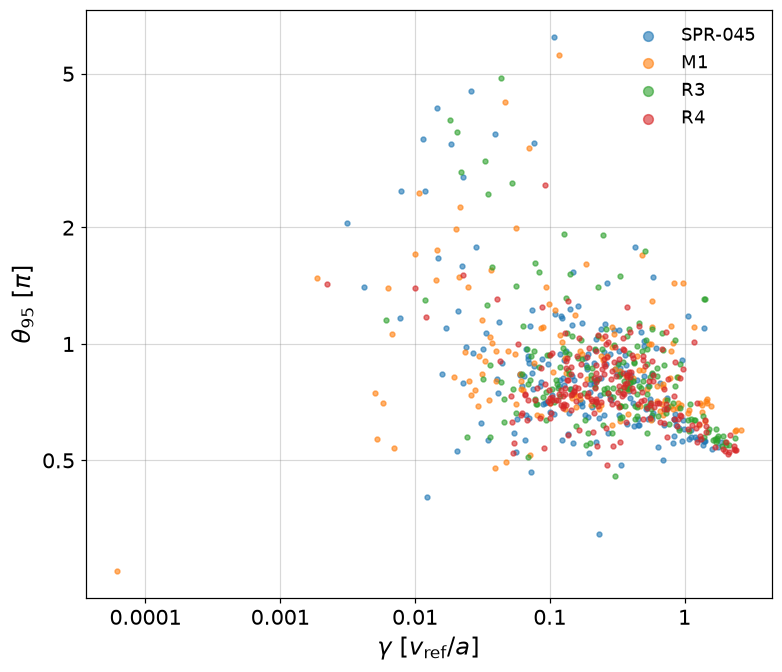

In [9]:
for database in databases:
    data = population[population.database == database]
    print(database, "Spearman(extent, gamma):", round(stats.spearmanr(data.extent, data.gamma).statistic, 3))
fig, ax = plt.subplots(figsize=(7, 6))
for database in databases:
    data = population[population.database == database]
    ax.scatter(data.gamma, data.extent, s=10, alpha=0.6, c=colour[database], label=database)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$\gamma$ [$v_{\rm ref}/a$]"); ax.set_ylabel(r"$\theta_{95}$ [$\pi$]"); plain_ticks(ax)
ax.legend(markerscale=2)
fig.savefig(plot_dir / "fig4_extent_vs_growth_rate.png")

## Verdict table

Pooled Tobit exponent (shared, one prefactor per database) with 95 % bootstrap CI, drop-one $\Delta$AIC, and the implied change of $\theta_{95}$ from the 5th to the 95th percentile of the parameter in the population. "Depends" = CI excludes 0 and drop-one $\Delta$AIC > 10.

In [10]:
verdict_rows = []
for name in sampled:
    slope, ci = slopes(pooled)[name], pooled["ci"][len(databases) + sampled.index(name)]
    p5, p95 = np.percentile(population[name], [5, 95])
    verdict_rows.append(dict(parameter=name, slope=slope, ci=ci, n=pooled["n"], dAIC_drop=drop_one["pooled"][name],
                             change_p5_p95=(p95 / p5) ** slope - 1, shared_p=sharing[name]["p"], dAIC_curvature=curvature[name],
                             verdict="depends" if abs(slope) > ci and drop_one["pooled"][name] > 10 else "no dependence found"))
verdicts = pd.DataFrame(verdict_rows)
print(verdicts.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

             parameter   slope     ci   n  dAIC_drop  change_p5_p95  shared_p  dAIC_curvature             verdict
                    ky  0.0691 0.0241 716       28.2          0.286    0.0984         -0.0797             depends
                     q  0.0136  0.107 716      -1.91         0.0174     0.936           -15.6 no dependence found
                  shat -0.0729 0.0336 716       14.2         -0.158    0.0348           -12.5             depends
                  beta 0.00279 0.0392 716      -1.97        0.00987     0.233           -14.8 no dependence found
     ion_temp_gradient  0.0853 0.0369 716       14.3          0.186     0.177               2             depends
electron_temp_gradient  0.0116 0.0281 716      -1.48         0.0295    0.0338            1.79 no dependence found
electron_dens_gradient -0.0353 0.0358 716       4.71         -0.104    0.0308          -0.777 no dependence found
           electron_nu  0.0174 0.0241 716     -0.248         0.0548     0.455           

## Figure 1. Extent against each parameter (marginal)

Every KBM in the population; circles kept, triangles box contact (lower bounds). Colour = database.

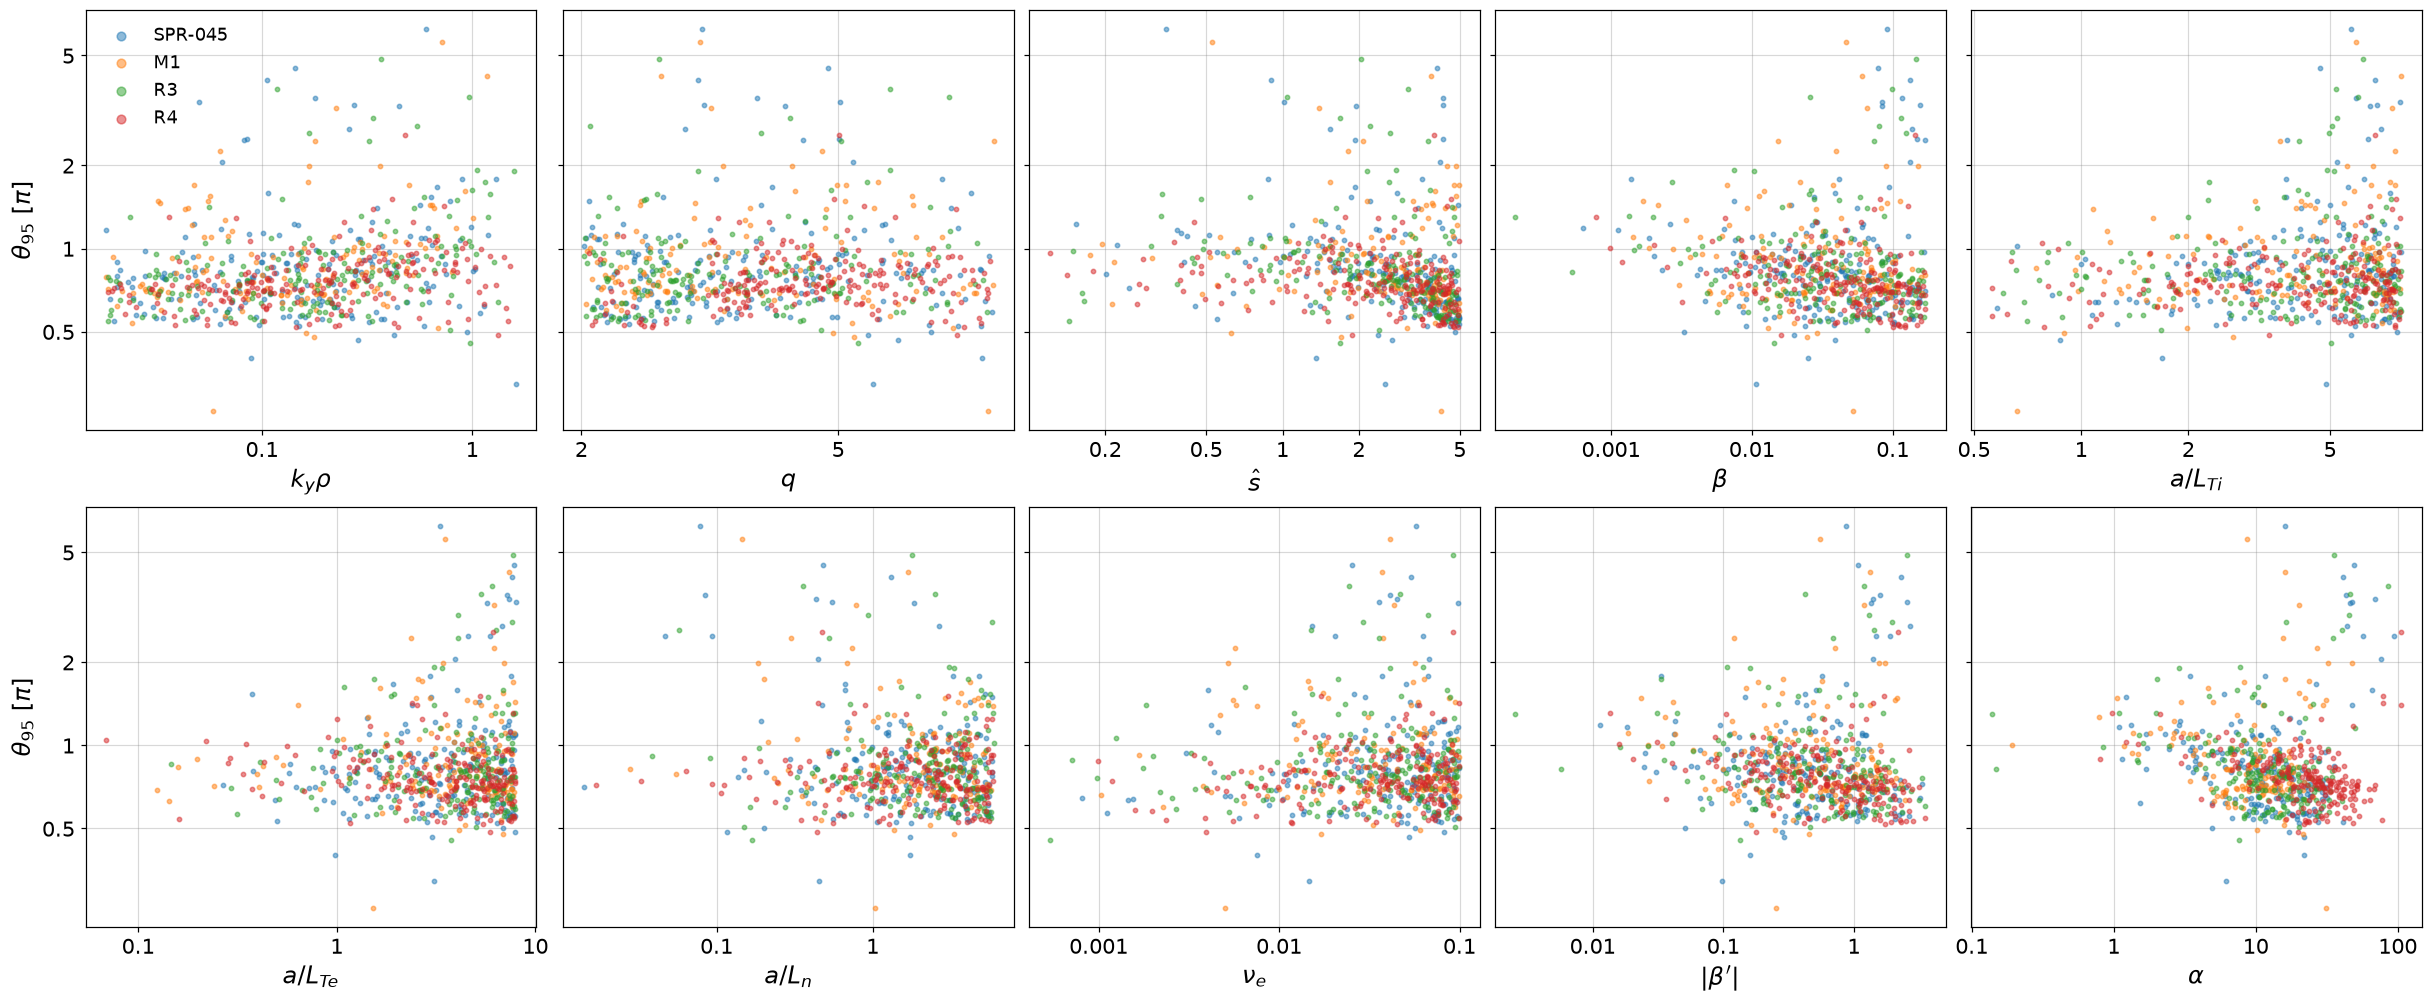

In [11]:
panels = sampled + derived
fig, axes = plt.subplots(2, 5, figsize=(22, 9), sharey=True)
for ax, name in zip(axes.flat, panels):
    for database in databases:
        data = population[population.database == database]
        ax.scatter(data[name][~data.censored], data.extent[~data.censored], s=8, alpha=0.5, c=colour[database], label=database)
        ax.scatter(data[name][data.censored], data.extent[data.censored], s=18, marker="^", alpha=0.7, c=colour[database])
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(symbol[name]); plain_ticks(ax)
for ax in axes[:, 0]: ax.set_ylabel(r"$\theta_{95}$ [$\pi$]")
axes[0, 0].legend(markerscale=2)
fig.savefig(plot_dir / "fig1_extent_vs_each_parameter.png")

## Figure 2. Partial residuals (pooled fit)

$\ln\theta_{95}$ minus the database intercept and every other parameter's term, against each parameter. Line: the fitted term.

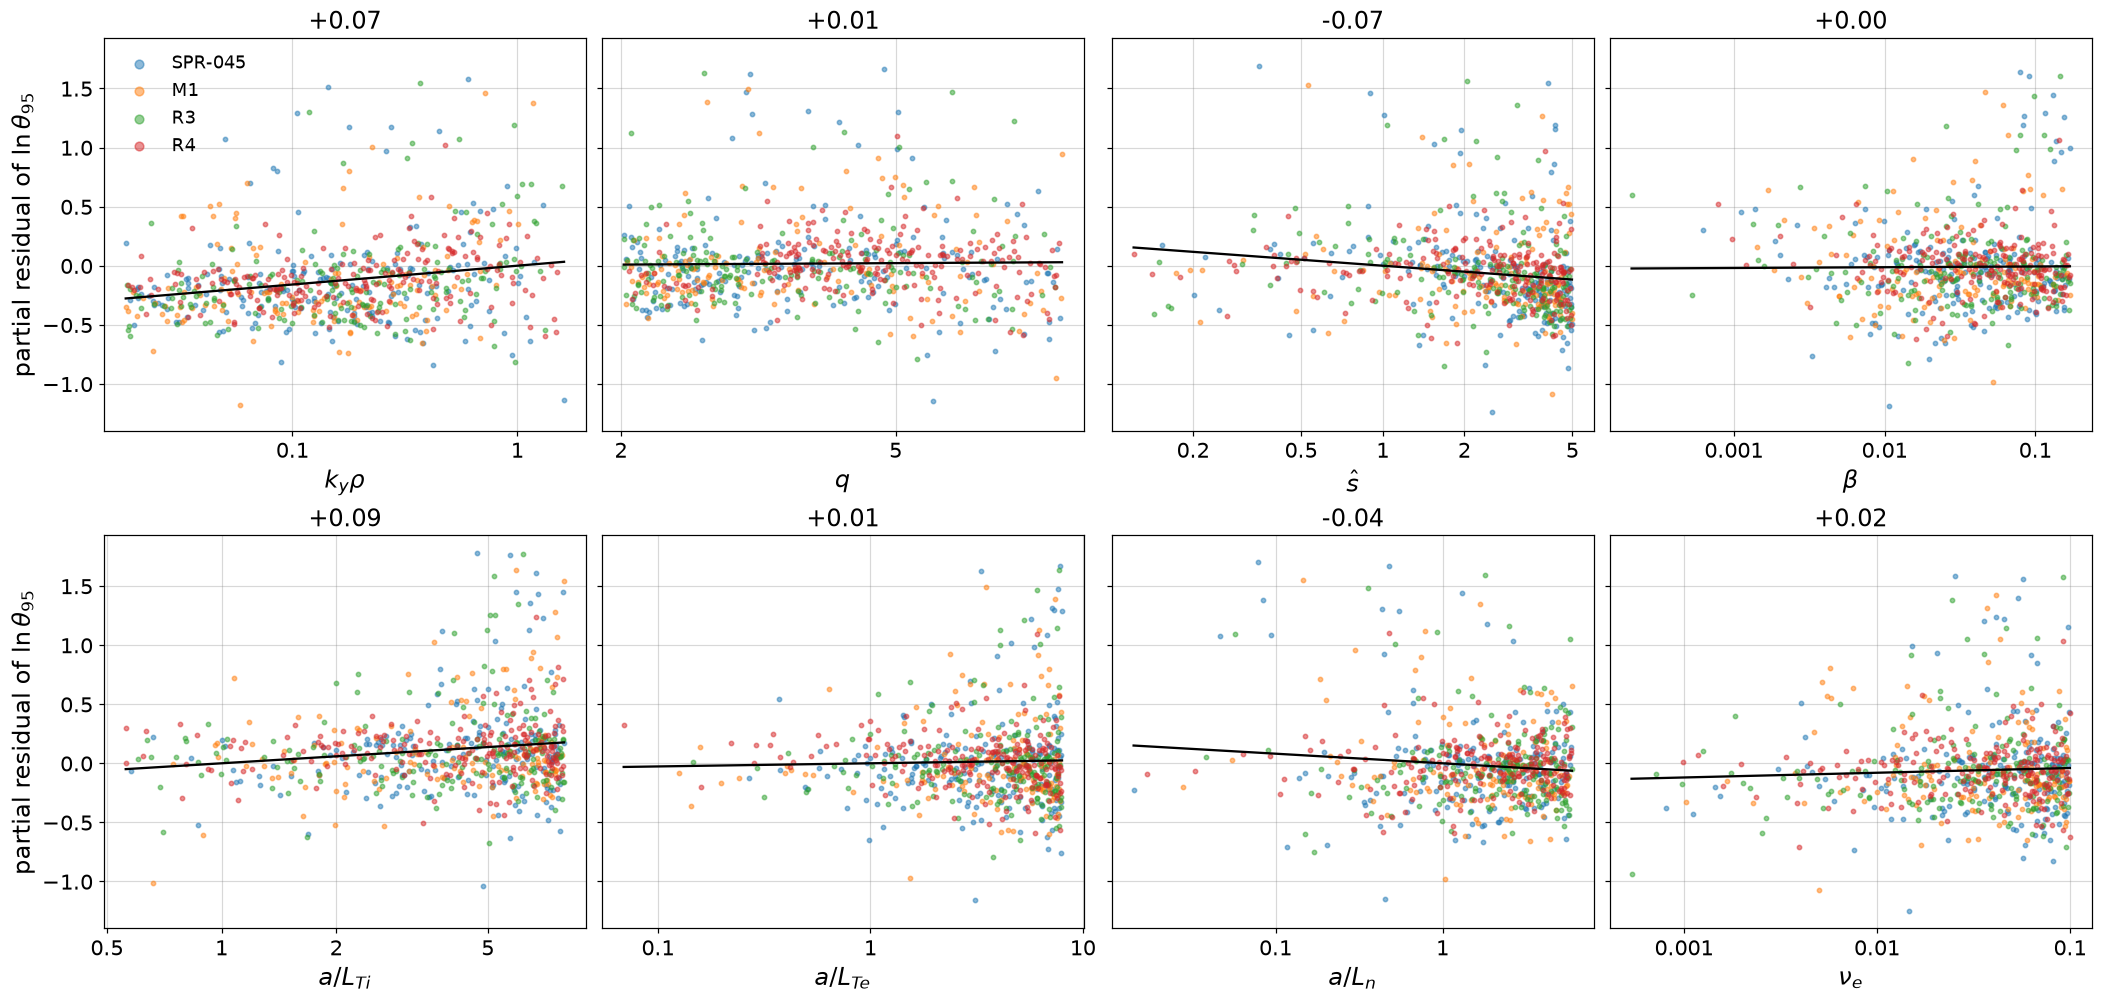

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9), sharey=True)
intercept_by_database = dict(zip(databases, pooled["b"][:len(databases)]))
full_prediction = design(population, sampled, tuple(databases)) @ pooled["b"]
for ax, name in zip(axes.flat, sampled):
    term = slopes(pooled)[name] * np.log(population[name])
    partial = np.log(population.extent) - full_prediction + term
    for database in databases:
        mask = population.database == database
        ax.scatter(population[name][mask & ~population.censored], partial[mask & ~population.censored], s=8, alpha=0.5, c=colour[database], label=database)
        ax.scatter(population[name][mask & population.censored], partial[mask & population.censored], s=18, marker="^", alpha=0.7, c=colour[database])
    grid = np.geomspace(population[name].min(), population[name].max(), 50)
    ax.plot(grid, slopes(pooled)[name] * np.log(grid), "k", lw=1.5, marker="")
    ax.set_xscale("log"); ax.set_xlabel(symbol[name]); ax.set_title(f"{slopes(pooled)[name]:+.2f}"); plain_ticks(ax)
for ax in axes[:, 0]: ax.set_ylabel(r"partial residual of $\ln\theta_{95}$")
axes[0, 0].legend(markerscale=2)
fig.savefig(plot_dir / "fig2_partial_residuals.png")

## Figure 3. Measured extent against the pooled power law, per database

y = x is the fitted centre (shared exponents, that database's prefactor). Triangles: lower bounds.

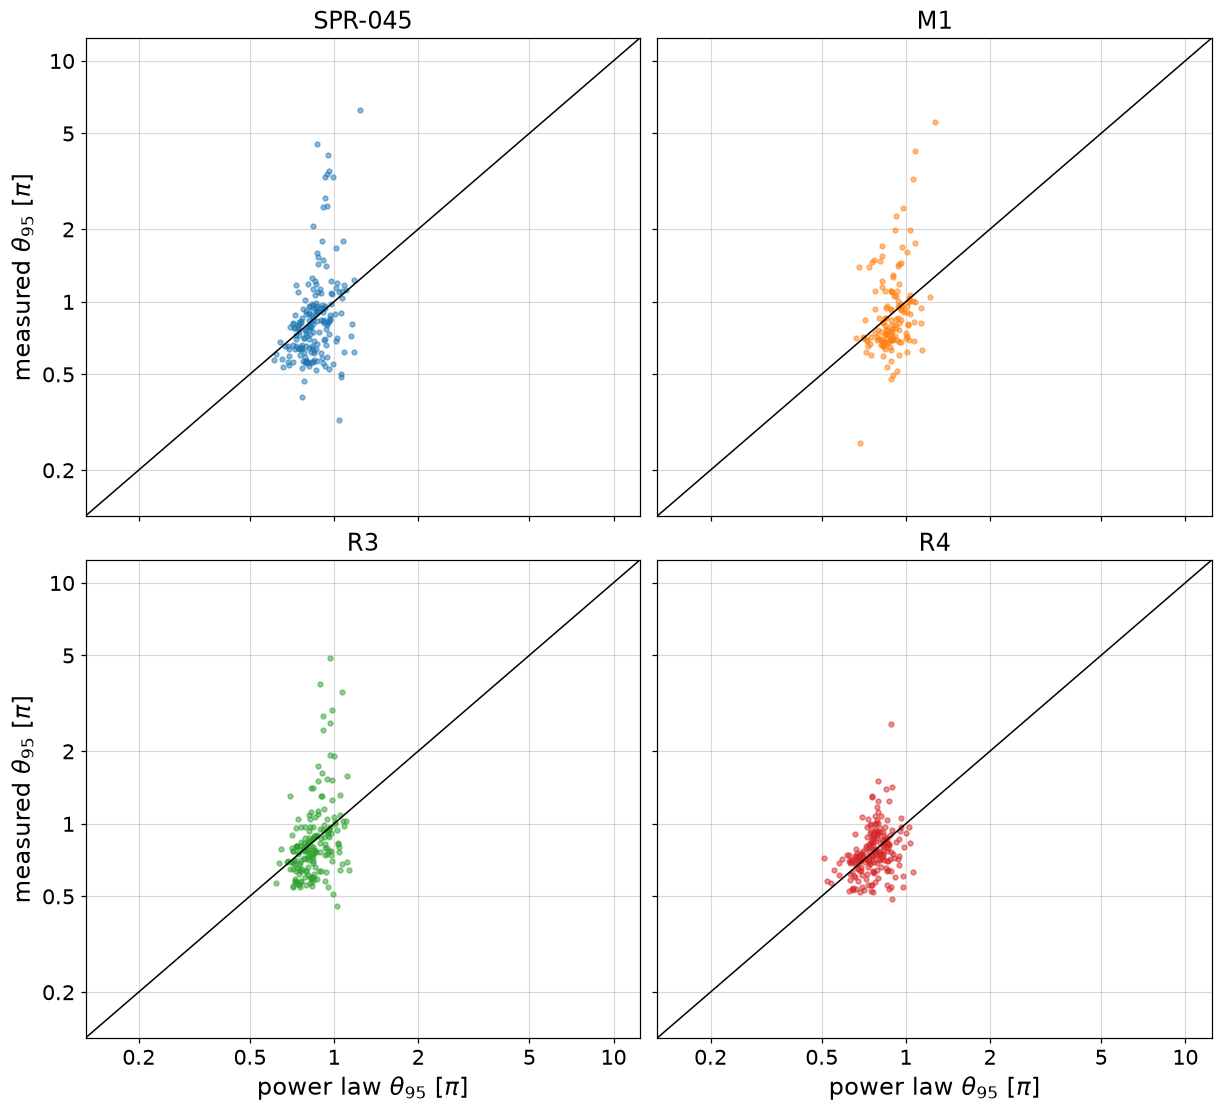

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
centre = np.exp(full_prediction)
limits = np.array([0.5 * min(centre.min(), population.extent.min()), 2 * max(centre.max(), population.extent.max())])
for ax, database in zip(axes.flat, databases):
    mask = (population.database == database).values
    ax.scatter(centre[mask & ~population.censored.values], population.extent[mask & ~population.censored.values], s=10, alpha=0.5, c=colour[database])
    ax.scatter(centre[mask & population.censored.values], population.extent[mask & population.censored.values], s=22, marker="^", alpha=0.8, c="k")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(limits); ax.set_ylim(limits)
    ax.plot(limits, limits, "k", lw=1, marker=""); ax.set_title(database); plain_ticks(ax)
for ax in axes[1]: ax.set_xlabel(r"power law $\theta_{95}$ [$\pi$]")
for ax in axes[:, 0]: ax.set_ylabel(r"measured $\theta_{95}$ [$\pi$]")
fig.savefig(plot_dir / "fig3_measured_vs_power_law.png")

## $\phi$-only extent

Same population; how far the $\phi$-only extent differs from $|\phi|^2+|A_\parallel|^2$, and the pooled fit on it (censoring flag unchanged).

In [14]:
ratio = population.extent_phi / population.extent
print("phi-only / (phi+apar) extent: median", round(float(ratio.median()), 4), "p5-p95", np.round(np.percentile(ratio, [5, 95]), 4))
phi_fit = tobit(population.assign(extent=population.extent_phi), sampled, tuple(databases))
print("pooled exponents, phi only:", "  ".join(f"{k} {v:+.3f}" for k, v in slopes(phi_fit).items()))

phi-only / (phi+apar) extent: median 1.0005 p5-p95 [0.9412 1.1121]


pooled exponents, phi only: ky +0.063  q +0.080  shat -0.084  beta +0.006  ion_temp_gradient +0.095  electron_temp_gradient +0.009  electron_dens_gradient -0.031  electron_nu +0.022


In [15]:
summary = dict(counts=counts.reset_index().rename(columns={"index": "database"}).to_dict("records"),
               fits={g: dict(slopes=slopes(f), ci=dict(zip(sampled, map(float, f["ci"][f["n_intercepts"]:]))),
                             prefactor=dict(zip(databases if g == "pooled" else [g], map(float, np.exp(f["b"][:f["n_intercepts"]])))),
                             sigma=f["sigma"], r2=f.get("r2"), n=f["n"], n_censored=f["n_censored"], drop_one_dAIC=drop_one[g]) for g, f in fits.items()},
               sharing=dict(all=dict(LR=lr_all, df=extra_df, p=stats.chi2.sf(lr_all, extra_df)), per_parameter=sharing), curvature_dAIC=curvature,
               derived={name: dict(dAIC_vs_beta=f["aic"] - pooled["aic"], exponent=slopes(f)[name]) for name, f in derived_fits.items()},
               verdicts=verdicts.to_dict("records"), distribution=distribution.reset_index().to_dict("records"),
               tail=dict(n=int(extended.sum()), comparison=comparison.to_dict("records"), ideal_unstable_tail=float(ideally_unstable[extended].mean()), ideal_unstable_bulk=float(ideally_unstable[~extended].mean())), phi_only=dict(median_ratio=float(ratio.median()), slopes=slopes(phi_fit)))
json.dump(summary, open(plot_dir / "summary.json", "w"), indent=1, default=float)